In [5]:
install.packages("rcarbon")
install.packages("here")

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [1]:
library(rcarbon)
library(here)
library(sp)
library(raster)
library(sf)

here() starts at /home/mat150604/Documentos/proyectos/clasePUC

Linking to GEOS 3.13.0, GDAL 3.9.2, PROJ 9.5.0; sf_use_s2() is TRUE



In [2]:
pts2<- read.csv(here("data/18072025_tocones.csv"))
#pts2<- read.csv(here("data/raw-data/p3k14c_data.csv"))
class(pts2)

[1] "data.frame"

In [3]:
# Convert to a SpatialPoints class object:
sp::coordinates(pts2) <- c("Lon","Lat")
class(pts2)
# Setting the CRS to EPSG:4326 (WGS84)
sp::proj4string(pts2) <- CRS("+init=epsg:4326")
# Transforming to EPSG:32719 (SAD69 / UTM zone 19S)
pts22 <- sp::spTransform(pts2, CRS("+init=epsg:32719"))
# Check the CRS of the transformed object
sp::proj4string(pts22)

[1] "SpatialPointsDataFrame"
attr(,"package")
[1] "sp"

[1] "+proj=utm +zone=19 +south +datum=WGS84 +units=m +no_defs"

In [4]:
# Run the calibration
x <- calibrate(x=pts22$C14Age, errors=pts22$C14SD, normalised=FALSE,verbose=FALSE,calCurves=pts22$calCurves)
# Bin preparation
bins1 <- binPrep(sites=pts22$SiteID, ages=pts22$C14Age,h=1000)
nsim=100
ncores=3
# Permutation test
#perm.emedyd=permTest(x=x,marks=pts22$Sitio,timeRange=c(19000,0),bins=bins1,nsim=nsim,runm=50)
perm.emedyd=permTest(x=x,marks=pts22$eleva,timeRange=c(19000,0),bins=bins1,nsim=nsim,runm=100)


[1] "Summing observed groups..."
  |======================================================================| 100%
[1] "Permuting the groups..."
  |======================================================================| 100%
[1] "Done."


In [5]:
summary(perm.emedyd)    

'permTest()' function summary:

Number of sets: 2
Statistical Significance computed using 100 simulations. 

--- 700-1000 ---
Number of radiocarbon dates:74
Number of bins:74

Global p-value: 0.0099

Significant positive local deviations at:
8073~7752 BP 
183~28 BP 

Significant negative local deviations at:
16240~15671 BP 
2319~2105 BP 
1404~1375 BP 
1224~1131 BP 
1005~637 BP 

--- >1000 ---
Number of radiocarbon dates:40
Number of bins:40

Global p-value: 0.0099

Significant positive local deviations at:
16240~15671 BP 
2319~2105 BP 
1404~1375 BP 
1224~1131 BP 
1005~637 BP 

Significant negative local deviations at:
8073~7752 BP 
183~28 BP 



Warning message in stackspd(x = x, group = pts22$eleva, timeRange = c(19000, 0), :
“The group argument has been transformed into a factor”


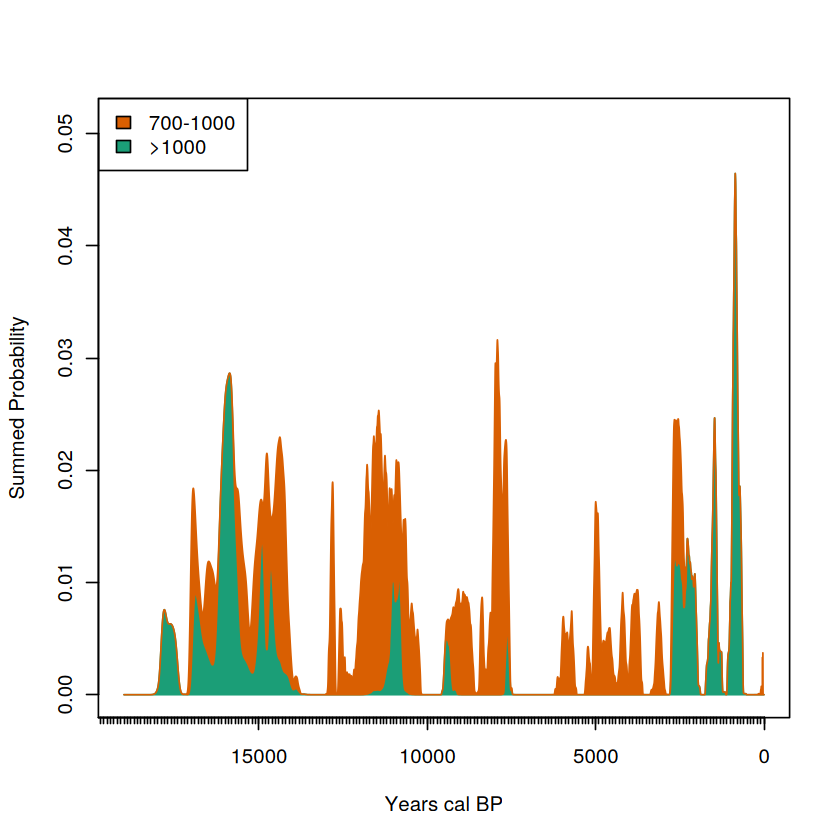

In [6]:
emedyd.spd=stackspd(x=x,group=pts22$eleva,timeRange=c(19000,0),bins=bins1,runm=100,verbos=FALSE)

plot(emedyd.spd,type='stacked')

[1] "Extracting and aggregating..."
[1] "Done."


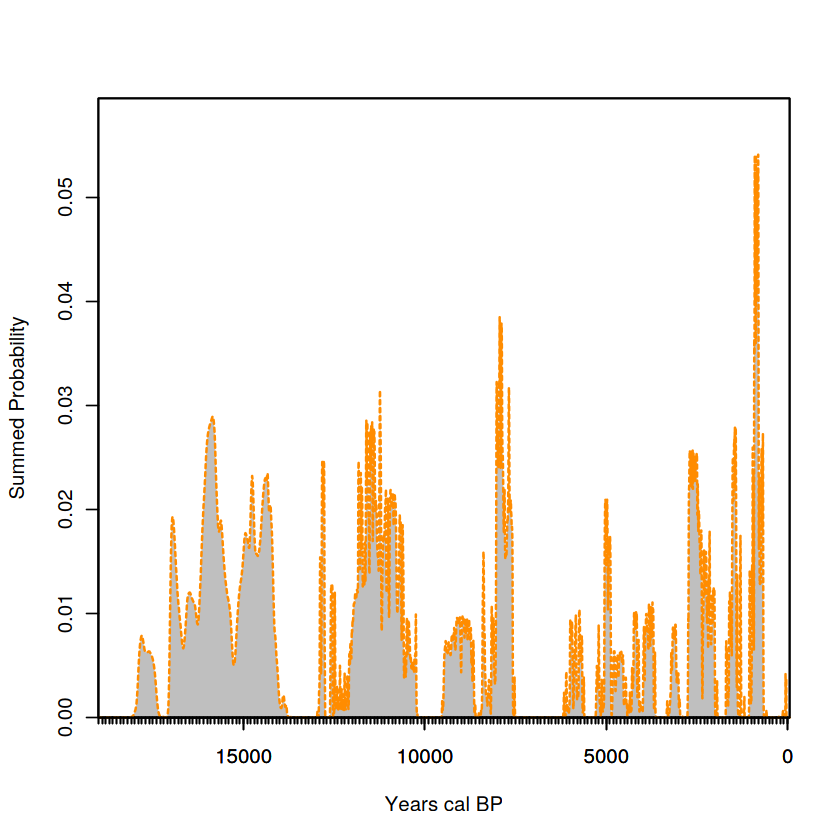

In [7]:
AFOREST.spd = spd(x,timeRange=c(19000,-60)) 
plot(AFOREST.spd)
plot(AFOREST.spd,add=TRUE,type="simple",col="darkorange",lwd=1.5,lty=2)

[1] "Computing SPDs..."
  |======================================================================| 100%
[1] "Done."
[1] "Extracting and aggregating..."
  |======================================================================| 100%
[1] "Done"


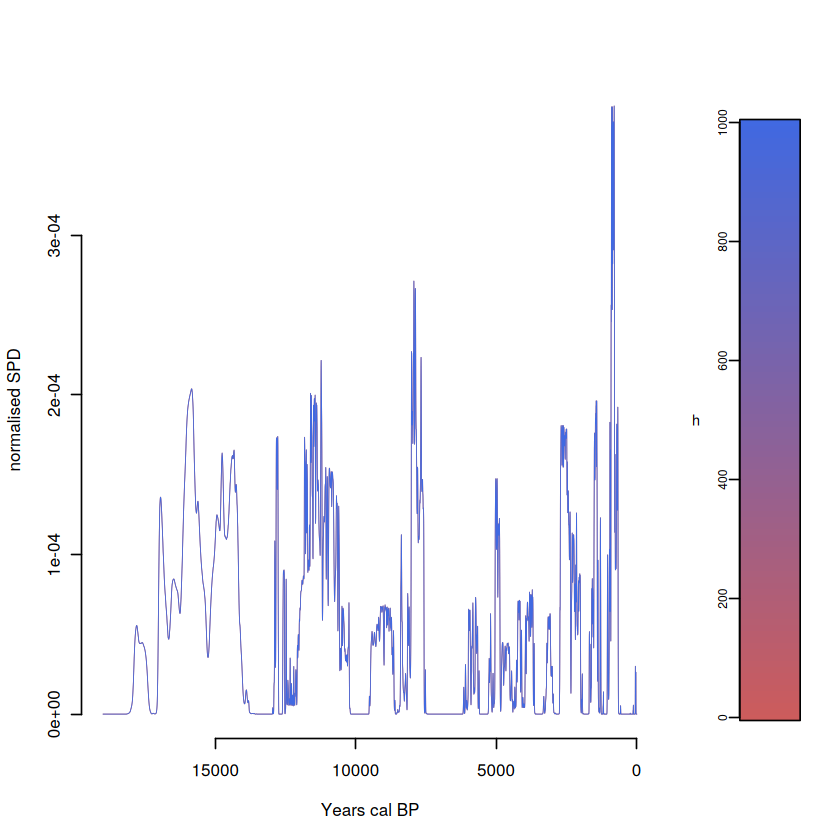

In [8]:
binsense(x=x,y=pts22$SiteID,h=seq(0,1000,1000),timeRange=c(19000,0)) 

x.bins.med=binMed(x = x, bins=bins1)

[1] "Extracting and aggregating..."
[1] "Done."


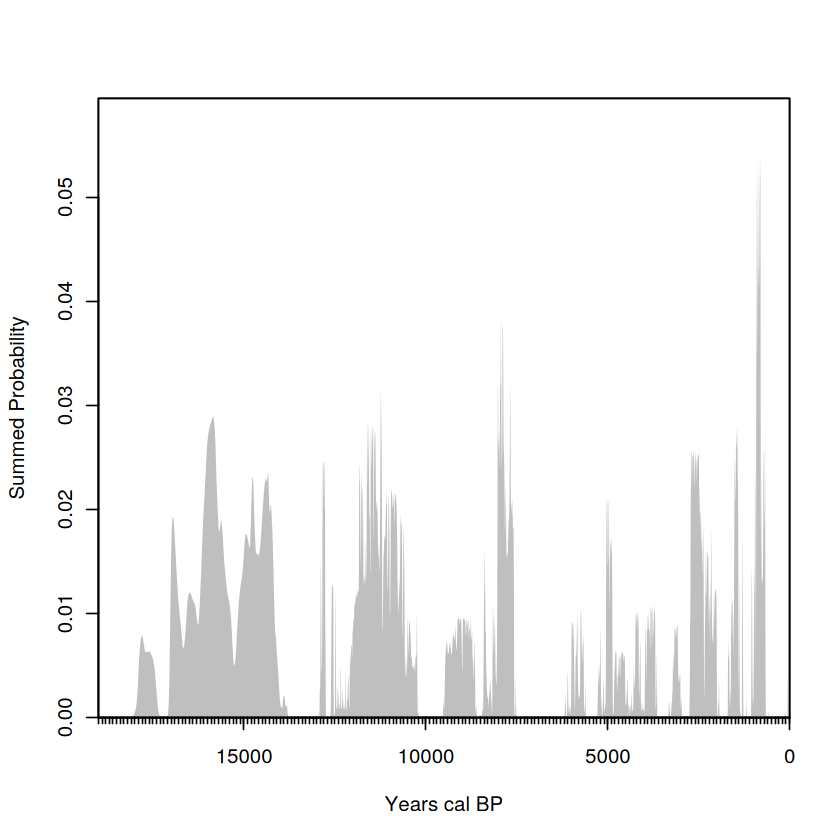

In [9]:
x <- calibrate(x=pts22$C14Age, errors=pts22$C14SD, normalised=F,verbose=F,calCurves=pts22$calCurves)
# subset CalDates object based on random thinning
x2 = x[thinDates(ages=pts22$C14Age,  errors=pts22$C14SD, bins=bins1, size=1, method='random')]


# aggregation and visualisation of the SPD
x2.thinned = spd(x2,timeRange=c(19000,0))
plot(x2.thinned)

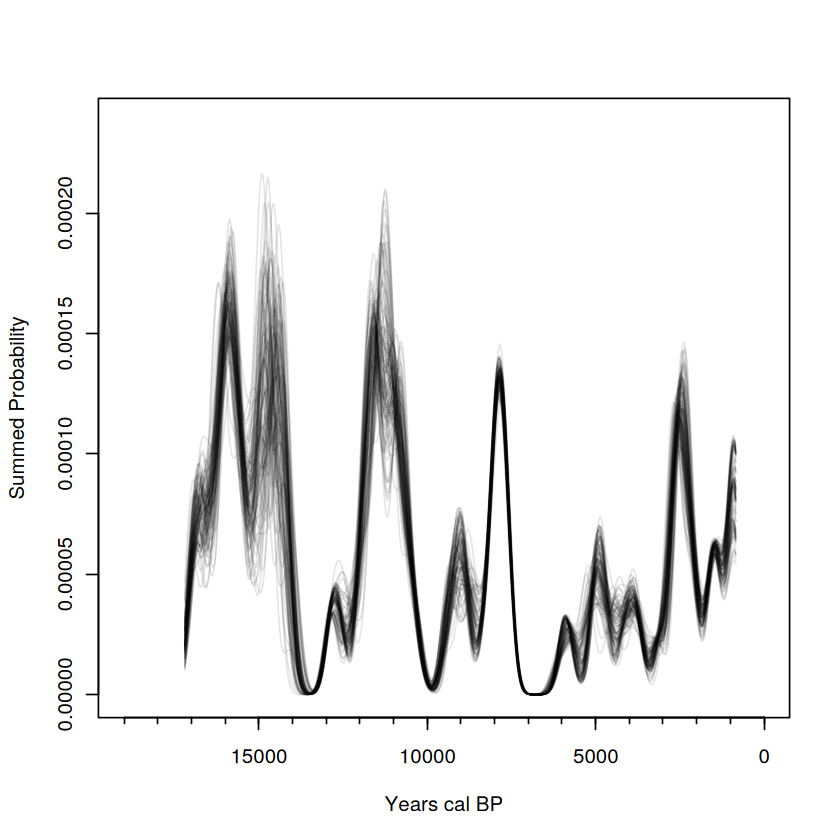

In [10]:
x.randates = sampleDates(x,bins=bins1,nsim=100,verbose=FALSE)
x.ckde = ckde(x.randates,timeRange=c(19000,0),bw=200)
plot(x.ckde,type='multiline')

In [11]:
library(sf)
library(spatstat.geom)

Loading required package: spatstat.data

Loading required package: spatstat.univar

spatstat.univar 3.0-1

spatstat.geom 3.3-3


Attaching package: ‘spatstat.geom’


The following objects are masked from ‘package:raster’:

    area, rotate, shift




Reading layer `mask' from data source 
  `/home/mat150604/Documentos/proyectos/clasePUC/data/mask.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 1 feature and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -69.74705 ymin: -21.54488 xmax: -68.98131 ymax: -20.96933
Geodetic CRS:  WGS 84


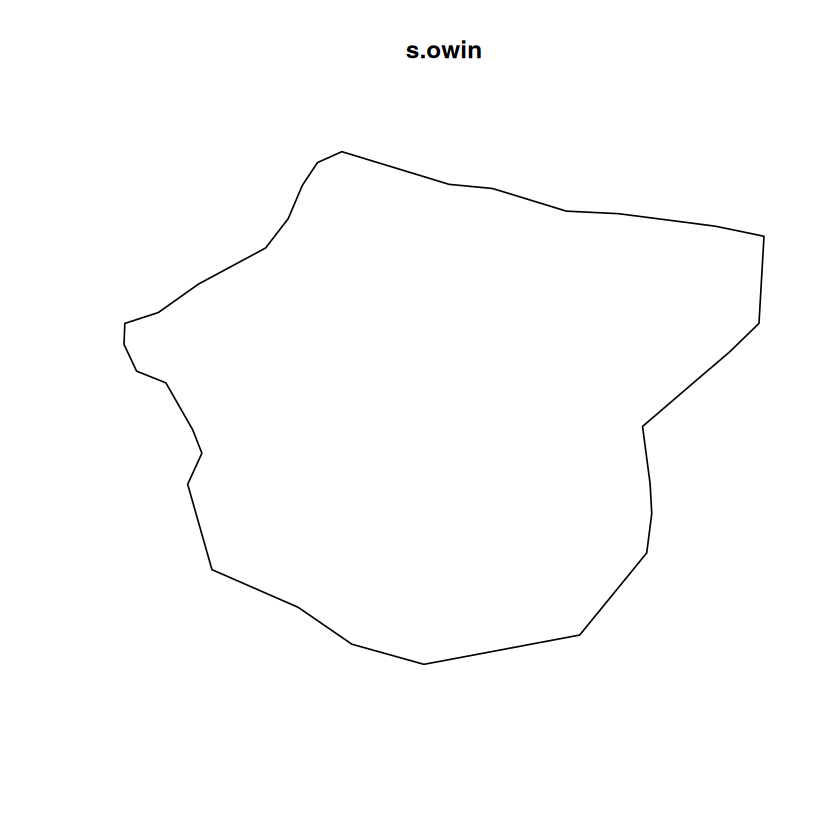

In [12]:
# Leer shapefile
s.sf <- st_read(here("data/mask.shp"))

# Reproyectar (usa EPSG:32719 para UTM 19S o EPSG:3857 si prefieres Web Mercator)
s.sf_proj <- st_transform(s.sf, 32719)

# Asegurar geometría válida
s.sf_proj <- st_make_valid(s.sf_proj)

# Convertir a objeto owin
s.owin <- as.owin(s.sf_proj)

# Graficar
plot(s.owin)

In [13]:
stkarch1 <- stkde(x=x, coords=pts22@coords, win=s.owin, sbw=8000, cellres=600, focalyears=seq(18000, 0, -100), tbw=200, bins=bins1, backsight=200, outdir=tempdir(), amount=1, verbose=FALSE)
if (!dir.exists("figures")) dir.create("figures")

In [14]:
#CAPE-I 
plot(stkarch1, seq(18000, 17000, -2000),main= "CAPE I: 18.000 to 17.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(17000, 16000, -2000),main= "CAPE I: 17.000 to 16.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(16000, 15000, -2000),main= "CAPE I: 16.000 to 15.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(15000, 14000, -2000),main= "CAPE I: 15.000 to 14.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(14000, 13000, -2000),main= "CAPE I: 14.000 to 13.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)


In [15]:
#CAPE-II 
plot(stkarch1, seq(13000, 12000, -2000),main= "CAPE II: 13.000 to 12.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(12000, 11000, -2000),main= "CAPE II: 12.000 to 11.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(11000, 10000, -2000),main= "CAPE II: 11.000 to 10.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(10000, 9000, -2000),main= "CAPE II: 10.000 to 9.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)


In [16]:
# Silencio Arqueologico
plot(stkarch1, seq(8000, 7000, -2000),main= "Archaeological Silence: 8.000 to 7.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(7000, 6000, -2000),main= "Archaeological Silence: 7.000 to 6.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(6000, 5000, -2000),main= "Archaeological Silence: 6.000 to 5.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(5000, 4000, -2000),main= "Archaeological Silence: 5.000 to 4.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(4000, 3000, -2000),main= "Archaeological Silence: 4.000 to 3.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)


In [17]:
# Current ENSO variability

plot(stkarch1, seq(3000, 2000, -1000),main= "Current ENSO variability: 3.000 to 2.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(2000, 1000, -1000),main= "Current ENSO variability: 2.000 to 1.000 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(1000, 500, -500),main= "Current ENSO variability: 1.000 to 500 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= F)
plot(stkarch1, seq(500, 100, -500),main= "Current ENSO variability: 500 to 200 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)
plot(stkarch1, seq(100, 0, -200),main= "Current ENSO variability: 200 to 0 cal a BP" , type="focal", ramptype=c("unl","unl","std"), plotdir = "figures/",imdim = c(10, 20), withpts= T)


[1] "Plotting to file..."
  |======================================================================| 100%
[1] "Done."
[1] "Plotting to file..."
  |======================================================================| 100%
[1] "Done."
[1] "Plotting to file..."
  |======================================================================| 100%
[1] "Done."
